# Laboratorium 5 — Warstwy splotowe

Wymagane pakiety: `torch`, `torchvision`, `matplotlib`, `numpy` i `Pillow`. Plik `zdjecie_lab05.png` powinien być w katalogu notebooka. Przy pierwszym uruchomieniu torchvision pobiera wagi ResNet-18.

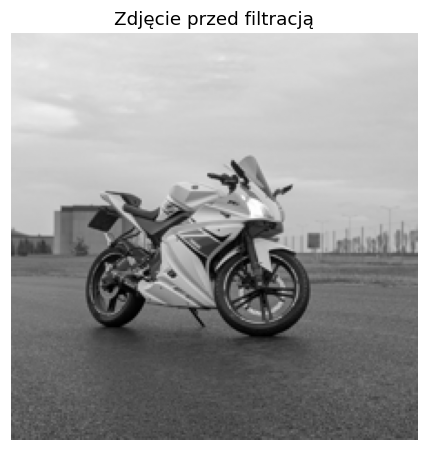

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from torch import nn
from torch.nn import functional as F
from torchvision.models import ResNet18_Weights, resnet18

pil = Image.open("zdjecie_lab05.png").convert("L")
gray = torch.from_numpy(np.array(pil)).float()[None, None] / 255

plt.imshow(gray[0, 0], cmap="gray", vmin=0, vmax=1)
plt.title("Zdjęcie przed filtracją")
plt.axis("off")
plt.show()

## 1. Ręczne jądra

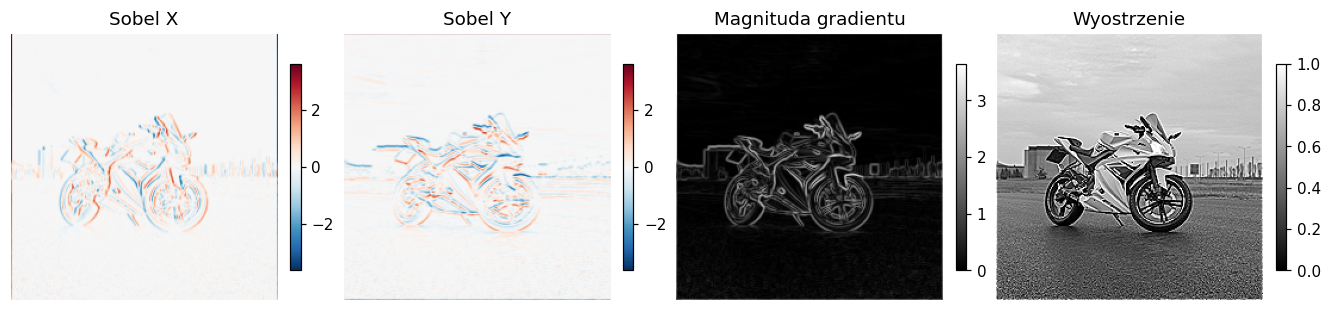

In [2]:
sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
sobel_y = sobel_x.T.contiguous()
sharpen = torch.tensor([[0., -1., 0.], [-1., 5., -1.], [0., -1., 0.]])

def apply_kernel(kernel, **kwargs):
    return F.conv2d(gray, kernel[None, None], **kwargs)[0, 0]

gx = apply_kernel(sobel_x, padding=1)
gy = apply_kernel(sobel_y, padding=1)
magnitude = (gx.square() + gy.square()).sqrt()
sharp = apply_kernel(sharpen, padding=1).clamp(0, 1)
limit = max(gx.abs().max().item(), gy.abs().max().item())

fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, title, data, cmap, lo, hi in zip(
    axes, ["Sobel X", "Sobel Y", "Magnituda gradientu", "Wyostrzenie"],
    [gx, gy, magnitude, sharp], ["RdBu_r", "RdBu_r", "gray", "gray"],
    [-limit, -limit, 0, 0], [limit, limit, magnitude.max().item(), 1],
):
    im = ax.imshow(data, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, shrink=0.65)
fig.savefig("jadra_reczne.png", dpi=150)
plt.show()

Sobel X reaguje na pionowe krawędzie, a Sobel Y na poziome. Kolor pokazuje znak zmiany jasności. Magnituda łączy obie odpowiedzi. Wyostrzenie zwiększa kontrast przy krawędziach.

## 2. Wymiary wyjścia

Dla każdej osi: $\left\lfloor (N + 2p - d(k-1) - 1)/s \right\rfloor + 1$.

In [3]:
height, width = gray.shape[-2:]
configs = [(3, 1, 1, 1), (3, 2, 1, 1), (3, 1, 0, 1),
           (3, 1, 1, 2), (5, 1, 2, 1), (3, 1, 2, 2)]

print("| k | s | p | d | Ze wzoru (H×W) | nn.Conv2d (H×W) |")
print("|---|---|---|---|---|---|")
for k, s, p, d in configs:
    expected = tuple((size + 2*p - d*(k-1) - 1)//s + 1
                     for size in (height, width))
    layer = nn.Conv2d(1, 1, k, stride=s, padding=p, dilation=d)
    with torch.inference_mode():
        actual = tuple(layer(gray).shape[-2:])
    assert actual == expected
    print(f"| {k} | {s} | {p} | {d} | {expected[0]}×{expected[1]} "
          f"| {actual[0]}×{actual[1]} |")

| k | s | p | d | Ze wzoru (H×W) | nn.Conv2d (H×W) |
|---|---|---|---|---|---|
| 3 | 1 | 1 | 1 | 224×224 | 224×224 |
| 3 | 2 | 1 | 1 | 112×112 | 112×112 |
| 3 | 1 | 0 | 1 | 222×222 | 222×222 |
| 3 | 1 | 1 | 2 | 222×222 | 222×222 |
| 5 | 1 | 2 | 1 | 224×224 | 224×224 |
| 3 | 1 | 2 | 2 | 224×224 | 224×224 |


## 3. Wpływ stride, padding i dilation

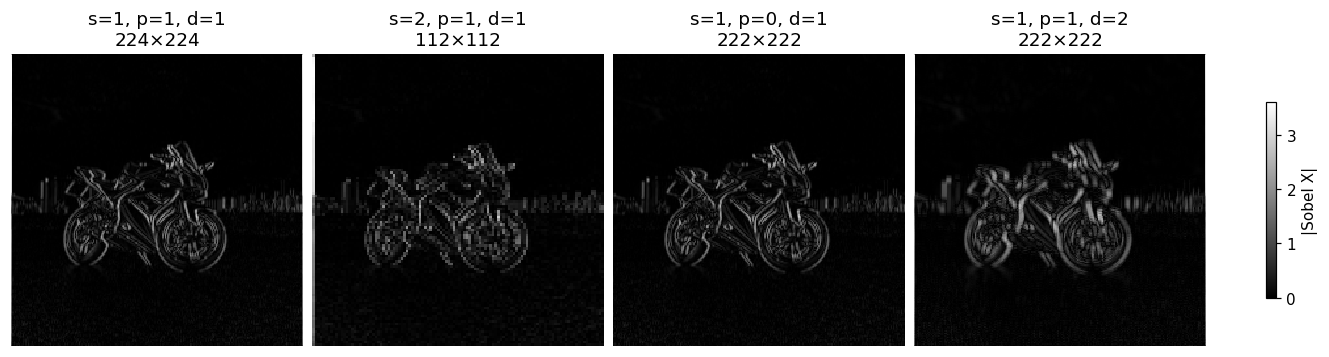

In [4]:
settings = [(1, 1, 1), (2, 1, 1), (1, 0, 1), (1, 1, 2)]
maps = [apply_kernel(sobel_x, stride=s, padding=p, dilation=d).abs()
        for s, p, d in settings]
limit = max(out.max().item() for out in maps)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2), layout="constrained")
for ax, (s, p, d), out in zip(axes, settings, maps):
    im = ax.imshow(out, cmap="gray", vmin=0, vmax=limit, interpolation="nearest")
    h, w = out.shape
    ax.set_title(f"s={s}, p={p}, d={d}\n{h}×{w}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.65, label="|Sobel X|")
fig.savefig("parametry_splotu.png", dpi=150)
plt.show()

Przy zmianie jednego parametru względem pierwszego panelu krok 2 zmniejsza rozdzielczość o połowę w obu osiach, brak dopełnienia usuwa skrajne pozycje odpowiedzi, a dylatacja 2 zwiększa efektywny rozmiar jądra z 3×3 do 5×5.

## 4. Mapy cech ResNet-18

Kształt map: (64, 112, 112) (C, H, W)


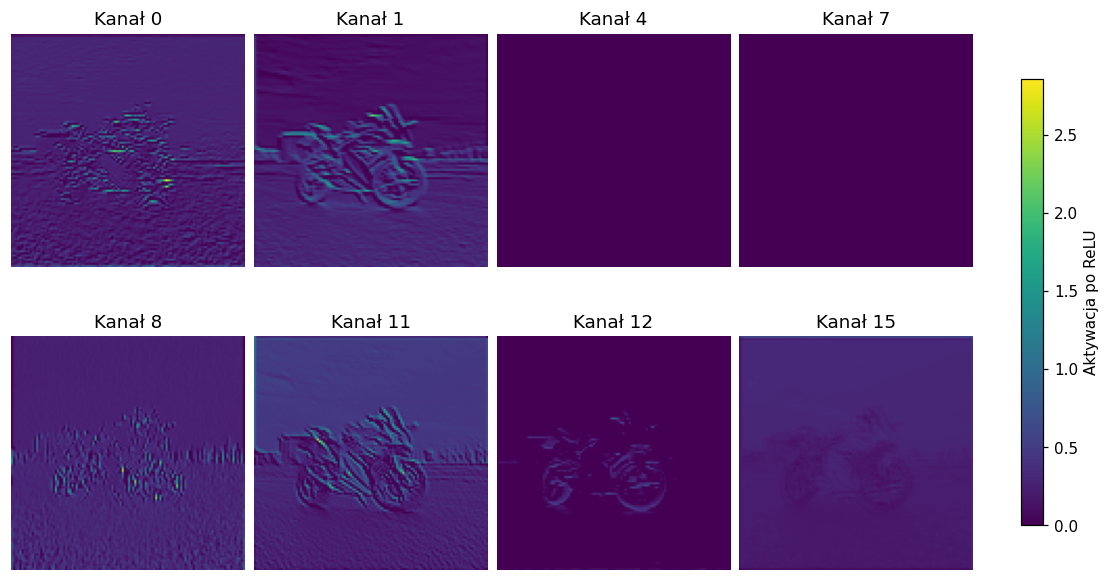

In [5]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).eval()

rgb = gray.repeat(1, 3, 1, 1)
mean = torch.tensor([0.485, 0.456, 0.406])[None, :, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[None, :, None, None]
x = (rgb - mean) / std

with torch.inference_mode():
    activations = model.relu(model.bn1(model.conv1(x)))[0]

channels = [0, 1, 4, 7, 8, 11, 12, 15]
selected = activations[channels]
print(f"Kształt map: {tuple(activations.shape)} (C, H, W)")
fig, axes = plt.subplots(2, 4, figsize=(10, 5.5), layout="constrained")
for channel, act, ax in zip(channels, selected, axes.flat):
    im = ax.imshow(act, cmap="viridis", vmin=0, vmax=selected.max().item())
    ax.set_title(f"Kanał {channel}")
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.75, label="Aktywacja po ReLU")
fig.savefig("mapy_cech.png", dpi=150)
plt.show()

Kanał 1 uwydatnia fragmenty horyzontu, kanał 8 pionowe detale, a kanał 11 skośne krawędzie owiewek. Kanał 12 reaguje między innymi na fragmenty obręczy.

## 5. Porównanie filtrów Box i Gaussian

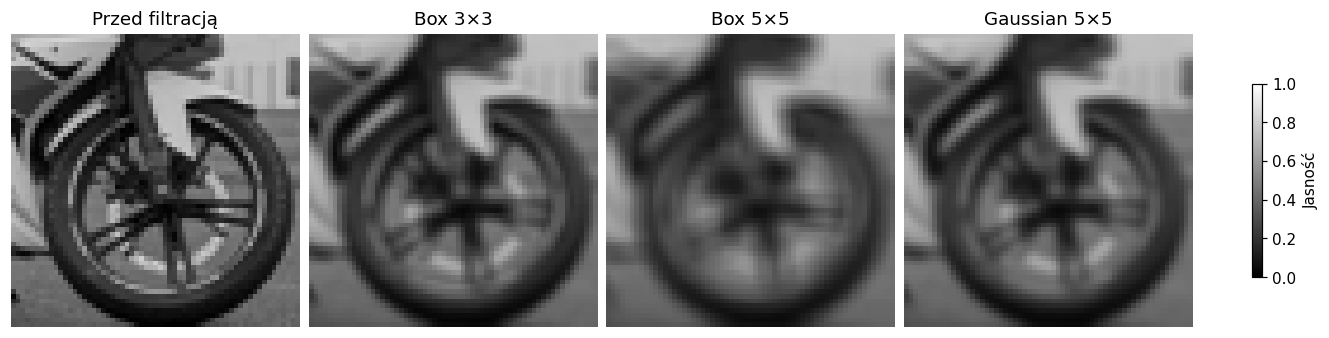

In [6]:
vector = torch.tensor([1., 4., 6., 4., 1.])
blur_kernels = {
    "Box 3×3": torch.ones(3, 3) / 9,
    "Box 5×5": torch.ones(5, 5) / 25,
    "Gaussian 5×5": torch.outer(vector, vector) / 256,
}
results = {"Przed filtracją": gray[0, 0]}
for name, kernel in blur_kernels.items():
    results[name] = apply_kernel(
        kernel, stride=1, padding=kernel.shape[0]//2, dilation=1
    )
    assert results[name].shape == gray.shape[-2:]

rows, cols = slice(105, 167), slice(105, 166)
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for (name, out), ax in zip(results.items(), axes):
    im = ax.imshow(out[rows, cols], cmap="gray", vmin=0, vmax=1,
                   interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.65, label="Jasność")
fig.savefig("porownanie_rozmycia.png", dpi=150)
plt.show()

Po Box 5×5 szprychy są mniej czytelne niż po Box 3×3. Gaussian 5×5 zachowuje wyraźniejsze granice szprych niż Box 5×5 dzięki większym wagom w środku okna.